# Pjesa I · 2/4: Pastrimi final i të dhënave

**Pyetja e analizës:** si ndryshon çmimi për natë i listimeve Airbnb në Londër? Për ta analizuar, na duhet një tabelë me çmim të vlefshëm, pa dublikatë, me mungesa të shpjeguara dhe pa çmime që janë gabime të dukshme.

Ky notebook e ndërton atë tabelë nga skedari origjinal i Inside Airbnb, i cili nuk ndryshohet kurrë. Çdo hap tregon çfarë bëhet, pse bëhet dhe sa rreshta ose vlera preken.

| Hapi | Çfarë bëhet |
|---|---|
| 1. Pastrimi bazë | heqim kolonat krejt bosh dhe ID-të e dyfishta; çmimin, datat dhe fushat `t/f` i kthejmë në tipet e duhura |
| 2. Mungesat | heqim listimet pa çmim (me arsyetim); plotësojmë `bathrooms`, `bedrooms`, `beds` dhe fushat e tjera ku ka kuptim; të tjerat i lëmë bosh me qëllim |
| 3. Vlerat ekstreme dhe anomalitë | heqim çmimet e pabesueshme (mbi percentilin 99.9 të llojit të dhomës), shënojmë ato mbi percentilin 99, kufizojmë `maximum_nights` në 1,125 dhe shënojmë listimet me më shumë `bedrooms` se `accommodates` |
| 4. Vetitë e reja | `has_reviews`, `is_superhost`, `price_band` dhe `amenity_count` |
| 5. Zgjedhja e vetive | 18 kolona të lidhura me pyetjen e analizës |
| 6. Transformimi | standardizim, kodim 0/1 dhe çmimi median sipas llojit të dhomës dhe lagjes |
| 7. Kontrolli dhe ruajtja | para/pas, çfarë ndodhi me çdo rresht dhe çdo mungesë, kontrolle që ndalojnë ekzekutimin nëse ka mbetur problem |

**Dalja** (dy skedarë në `dataset/`):
- `listings_clean_full.csv` · tabela e plotë e pastruar, me të gjitha kolonat;
- `listings_preprocessed.csv` · tabela me 18 kolona për analizën e çmimit.

**Si ekzekutohet:** ekzekutoni së pari notebook-un 01 për të parë problemet fillestare, pastaj këtë nga rrënja e projektit ose nga `notebooks/`. Ai gjen vetë `dataset/listings.csv.gz`; për një skedar tjetër vendosni `PVDH_DATASET_PATH`. Skripti `scripts/clean_listings.py` kryen të njëjtin pastrim (hapat 1–3) nga rreshti i komandës.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings.csv.gz").is_file() and (ROOT.parent / "dataset" / "listings.csv.gz").is_file():
    ROOT = ROOT.parent
DATA_PATH = Path(os.environ.get("PVDH_DATASET_PATH", ROOT / "dataset" / "listings.csv.gz"))
assert DATA_PATH.is_file(), f"Mungon dataset-i: {DATA_PATH}"
raw = pd.read_csv(DATA_PATH, low_memory=False, dtype={"host_profile_id": "string"})
df = raw.copy()
log = []
removed = {}  # rreshtat e larguara dhe arsyeja
def record(step):
    log.append({"hapi": step, "rreshta": len(df), "kolona": df.shape[1], "qeliza boshe": int(df.isna().sum().sum())})
record("Fillimi")
print(f"Burimi: {DATA_PATH.name} | Fillimi: {len(df):,} rreshta × {df.shape[1]} kolona")

Burimi: listings.csv.gz | Fillimi: 91,954 rreshta × 90 kolona


## 1. Pastrimi bazë dhe tipet

Heqim kolonat 100% boshe dhe ID-të e përsëritura, por ruajmë `bathrooms`: megjithëse është bosh në këtë version, mund ta rindërtojmë nga `bathrooms_text`. Kthejmë `price` në numër duke larguar formatimin (`$`, presje). Datat ruhen si `datetime`, ndërsa `t/f` bëhet `True/False` pa e ngatërruar mungesën me `False`.

In [2]:
empty_columns = [col for col in df.columns[df.isna().all()] if col != "bathrooms"]
df = df.drop(columns=empty_columns)
removed["ID e dyfishuar"] = int(df["id"].duplicated().sum())
df = df.drop_duplicates(subset="id", keep="first").copy()
df["price"] = pd.to_numeric(df["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
for col in ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]:
    if col in df:
        df[col] = pd.to_datetime(df[col], errors="coerce")
boolean_columns = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
for col in boolean_columns:
    if col in df:
        df[col] = df[col].map({"t": True, "f": False}).astype("boolean")
record("Kolona boshe, ID, tipe")
print(f"Kolona 100% boshe të hequra: {len(empty_columns)}: {', '.join(empty_columns)}")
print(f"ID të dyfishuara të hequra: {removed['ID e dyfishuar']}")
display(df[["price", "last_scraped", "host_is_superhost"]].dtypes.to_frame("tipi i korrigjuar"))

Kolona 100% boshe të hequra: 14: neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, calendar_updated, license, instant_bookable
ID të dyfishuara të hequra: 0


,tipi i korrigjuar
price,Float64
last_scraped,datetime64[ns]
host_is_superhost,boolean


## 2. Trajtimi i mungesave

`price` është variabla që duam të analizojmë. Nuk e plotësojmë me mesatare, sepse kjo do të krijonte çmime të sajuara; heqim rreshtat pa çmim. Para se t'i heqim, shohim cilët janë: tabela e parë tregon se ata janë kryesisht jashtë shitjes (pa ditë të lira në vitin e ardhshëm) dhe vijnë shpesh nga një mbledhje e mëparshme (`source = 'previous scrape'`). Pra nuk humbasim listime të zakonshme. Tabela e dytë krahason listimet me çmim sipas burimit: çmimet e mbledhjes së mëparshme nuk duken të gabuara, prandaj mbeten.

Pastaj plotësojmë këto mungesa:
- `bathrooms` rindërtohet nga `bathrooms_text` (p.sh. *1.5 baths* → 1.5, *Half-bath* → 0.5, *No bathroom* → 0).
- `has_availability` merret nga `availability_365`: `True` kur listimi ka ditë të lira në vitin e ardhshëm.
- Për `bathrooms`, `bedrooms` dhe `beds`, mungesat e mbetura plotësohen me medianën e listimeve me të njëjtin `accommodates`, pastaj me medianën e përgjithshme. Kjo është supozim praktik dhe duhet përmendur si kufizim.
- Mungesat në rezultatet e komenteve ruhen: listimi pa komente nuk ka vlerësim. `reviews_per_month` bëhet 0 vetëm kur `number_of_reviews == 0`.

In [3]:
status = df["price"].isna().map({True: "pa çmim", False: "me çmim"}).rename(None)
display(pd.DataFrame({
    "listime": status.value_counts(),
    "% pa ditë të lira (availability_365 = 0)": df["availability_365"].eq(0).groupby(status).mean().mul(100),
    "% me burim 'previous scrape'": df["source"].eq("previous scrape").groupby(status).mean().mul(100),
}).round(1))

priced = df.dropna(subset=["price"])
by_source = priced["source"].eq("previous scrape").map({True: "previous scrape", False: "burime të tjera"}).rename(None)
display(priced.groupby(by_source).agg(
    listime=("id", "size"), cmimi_median=("price", "median"), dite_te_lira_mediane=("availability_365", "median")
).round(1))

removed["pa çmim"] = int(df["price"].isna().sum())
df = df.dropna(subset=["price"]).copy()
removed["çmim <= 0"] = int(df["price"].le(0).sum())
df = df[df["price"].gt(0)].copy()
record("Heqja e çmimit të munguar/jo pozitiv")
print(f"Pa çmim: {removed['pa çmim']:,}; çmim <= 0: {removed['çmim <= 0']:,}")

,listime,% pa ditë të lira (availability_365 = 0),% me burim 'previous scrape'
me çmim,59905,0.5,4.3
pa çmim,32049,87.3,92.7


,listime,cmimi_median,dite_te_lira_mediane
burime të tjera,57318,176.0,260.0
previous scrape,2587,149.0,33.0


Pa çmim: 32,049; çmim <= 0: 0


In [4]:
def bathrooms_from_text(bathrooms_text):
    # Numri te teksti si '1.5 shared baths'; 'Half-bath' është 0.5 dhe 'No bathroom' është 0.
    text = bathrooms_text.astype("string")
    numbers = text.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    half_bath = text.str.contains("half", case=False, na=False)
    no_bath = text.str.contains(r"^no bath", case=False, na=False)
    return numbers.mask(numbers.isna() & half_bath, 0.5).mask(numbers.isna() & no_bath, 0.0)

missing_bathrooms = int(df["bathrooms"].isna().sum())
df["bathrooms"] = df["bathrooms"].fillna(bathrooms_from_text(df["bathrooms_text"]))
print(f"bathrooms të rindërtuara nga bathrooms_text: {missing_bathrooms - int(df['bathrooms'].isna().sum()):,}")

missing_availability = int(df["has_availability"].isna().sum())
df["has_availability"] = df["has_availability"].fillna(df["availability_365"].gt(0))
print(f"has_availability të plotësuara nga availability_365: {missing_availability}")

imputations = {}
for col in ["bathrooms", "bedrooms", "beds"]:
    before = int(df[col].isna().sum())
    group_median = df.groupby("accommodates")[col].transform("median")
    df[col] = df[col].fillna(group_median).fillna(df[col].median())
    imputations[col] = before - int(df[col].isna().sum())
no_reviews = df["number_of_reviews"].eq(0)
df.loc[no_reviews & df["reviews_per_month"].isna(), "reviews_per_month"] = 0

# Numrat e dhomave dhe të viteve ruhen si numra të plotë (1, jo 1.0).
integer_columns = [col for col in ["bedrooms", "beds", "host_listings_count", "hosts_time_as_user_years",
                                   "hosts_time_as_user_months", "hosts_time_as_host_years",
                                   "hosts_time_as_host_months"] if col in df]
df[integer_columns] = df[integer_columns].round().astype("Int64")
record("Plotësimi i zgjedhur i mungesave")
display(pd.Series(imputations, name="vlera të plotësuara me medianë").to_frame())

bathrooms të rindërtuara nga bathrooms_text: 59,813
has_availability të plotësuara nga availability_365: 3


,vlera të plotësuara me medianë
bathrooms,92
bedrooms,24
beds,1502


## 3. Vlerat ekstreme dhe anomalitë

Një çmim i lartë mund të jetë gabim ose listim luksoz, prandaj e trajtojmë në dy hapa.

1. **Çmimet e pabesueshme hiqen.** Një çmim normal për një shtëpi të tërë mund të jetë gabim për një dhomë të vetme, prandaj kufiri është percentili 99.9 **i secilit lloj dhome**. Shembuj që hiqen: një dhomë private për 1 mysafir me çmim 75,000. Çmime të tilla shtrembërojnë mesataret dhe shkallëzimin. Kufizim: në grupet me më pak se 1,000 listime (`Shared room`, `Hotel room`) percentili 99.9 bie mes dy çmimeve më të larta, prandaj hiqet çmimi më i lartë i grupit.
2. **Çmimet e larta që mbeten vetëm shënohen.** Mbi percentilin 99 (të llogaritur pas hapit të parë) vendosim `price_above_p99`, por **nuk i fshijmë**: mund të jenë listime të vërteta luksoze. Histogrami përdor vetëm vlerat deri në këtë kufi që pjesa kryesore e të dhënave të lexohet qartë; tabela ruan të gjitha çmimet që mbeten.

In [5]:
PRICE_DROP_QUANTILE = 0.999
highest_price = df["price"].max()
drop_limits = df.groupby("room_type")["price"].quantile(PRICE_DROP_QUANTILE)
is_extreme = df["price"].gt(df["room_type"].map(drop_limits))
extreme_rows = df.loc[is_extreme, ["id", "room_type", "accommodates", "price"]].sort_values("price", ascending=False)
removed["çmim ekstrem"] = len(extreme_rows)
df = df[~is_extreme].copy()
record("Heqja e çmimeve ekstreme (P99.9 sipas llojit të dhomës)")
print(f"Çmimi më i lartë para heqjes: {highest_price:,.0f}; rreshta të hequr: {len(extreme_rows)}")
display(pd.DataFrame({
    "kufiri (P99.9)": drop_limits.round(0),
    "rreshta të hequr": extreme_rows["room_type"].value_counts().reindex(drop_limits.index, fill_value=0),
    "çmimi më i lartë i mbetur": df.groupby("room_type")["price"].max(),
}))
display(extreme_rows.head(10))

Çmimi më i lartë para heqjes: 75,000; rreshta të hequr: 59


,kufiri (P99.9),rreshta të hequr,çmimi më i lartë i mbetur
room_type,,,
Entire home/apt,6798.0,40,6798.4
Hotel room,1440.0,0,1440.0
Private room,5000.0,18,5000.0
Shared room,2083.0,1,622.5


,id,room_type,accommodates,price
9263,13254774,Private room,1,75000.0
59223,1289811437722717777,Private room,3,59214.0
53774,1203041287118705621,Private room,3,28000.0
53920,1183168933886992107,Private room,3,23686.0
54210,1207889725595849665,Entire home/apt,16,23520.0
61863,1342870516779702858,Entire home/apt,2,16318.4
55464,1196233560198207804,Entire home/apt,16,14744.0
42564,943540074261545116,Entire home/apt,2,12000.0
60961,1334074652906908090,Entire home/apt,16,10708.0
34324,644043613421252064,Entire home/apt,10,10679.0


P99: 1203.38; listime mbi kufi: 599


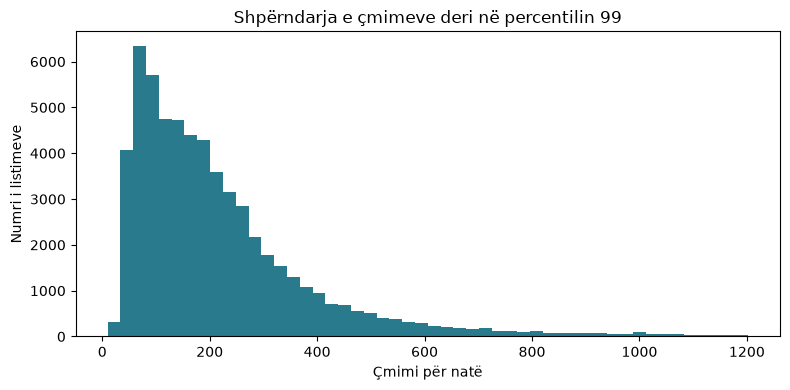

In [6]:
price_p99 = df["price"].quantile(0.99)
df["price_above_p99"] = df["price"].gt(price_p99)
print(f"P99: {price_p99:.2f}; listime mbi kufi: {int(df['price_above_p99'].sum()):,}")
ax = df.loc[~df["price_above_p99"], "price"].plot.hist(bins=50, figsize=(8, 4), color="#287a8c")
ax.set(xlabel="Çmimi për natë", ylabel="Numri i listimeve", title="Shpërndarja e çmimeve deri në percentilin 99")
plt.tight_layout()
plt.show()
record("Shënimi i çmimeve mbi P99")

### Anomali në kolona të tjera

Dy kolona kanë vlera të pazakonta që nuk janë gabime çmimi, prandaj këtu **nuk fshijmë rreshta**.

- **`maximum_nights`** (dhe kolonat e tjera të netëve maksimale) ka vlera si 2,147,483,647, kufiri i një numri të plotë 32-bit. Ajo nuk është një numër i vërtetë netësh, por një shenjë "pa kufi". Kufizojmë vlerat në 1,125, që është vlera maksimale e zakonshme dhe percentili 99 i dataset-it. Listimi mbetet, hiqet vetëm vlera absurde.
- **`bedrooms` > `accommodates`** (p.sh. 2 dhoma gjumi për 1 mysafir) është e pazakontë, por jo e pamundur. Tabela më poshtë tregon se pothuajse të gjitha janë dhoma private, ndaj ka gjasa që hosti të ketë shënuar dhomat e gjithë shtëpisë. Vlerën nuk e ndryshojmë; e shënojmë te `bedrooms_above_accommodates`, që analiza ta përjashtojë ose ta shqyrtojë.

In [7]:
MAX_NIGHTS_CAP = 1125
night_columns = [col for col in ["maximum_nights", "minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"] if col in df]
largest_nights = df[night_columns].max().max()
capped = (df[night_columns] > MAX_NIGHTS_CAP).sum()
df[night_columns] = df[night_columns].clip(upper=MAX_NIGHTS_CAP)
display(capped.to_frame(f"vlera mbi {MAX_NIGHTS_CAP:,} të kufizuara"))
print(f"Vlera më e madhe e netëve maksimale: {largest_nights:,.0f} para kufizimit, {df[night_columns].max().max():,.0f} pas tij")

df["bedrooms_above_accommodates"] = (df["bedrooms"] > df["accommodates"]).astype(bool)
flagged = df[df["bedrooms_above_accommodates"]]
print(f"bedrooms > accommodates: {len(flagged):,} listime ({len(flagged) / len(df):.1%}), të shënuara te bedrooms_above_accommodates")
display(flagged["room_type"].value_counts().to_frame("listime të shënuara"))
record("Anomali: maximum_nights i kufizuar, bedrooms > accommodates i shënuar")

,"vlera mbi 1,125 të kufizuara"
maximum_nights,23
minimum_maximum_nights,16
maximum_maximum_nights,23
maximum_nights_avg_ntm,22


Vlera më e madhe e netëve maksimale: 2,147,483,647 para kufizimit, 1,125 pas tij
bedrooms > accommodates: 375 listime (0.6%), të shënuara te bedrooms_above_accommodates


,listime të shënuara
room_type,
Private room,348
Entire home/apt,25
Hotel room,1
Shared room,1


## 4. Krijimi i vetive, binarizimi dhe diskretizimi

`has_reviews` dhe `is_superhost` janë veti binare. `price_band` e ndan çmimin në tri grupe sipas tercileve të këtij dataset-i. Nëse çmimi përdoret si variabël që parashikohet, **mos përdorni `price_band` si hyrje të modelit**: ajo është krijuar nga vetë çmimi. `amenity_count` numëron lehtësitë e listuara te `amenities`.

In [8]:
df["has_reviews"] = df["number_of_reviews"].gt(0)
df["is_superhost"] = df["host_is_superhost"].astype("boolean")
df["price_band"] = pd.qcut(df["price"], q=3, labels=["i ulët", "mesatar", "i lartë"], duplicates="drop")
df["amenity_count"] = df["amenities"].fillna("[]").astype(str).str.count('"') // 2
record("Vetitë e reja dhe kategoritë")
display(df[["price", "price_band", "has_reviews", "is_superhost", "amenity_count"]].head())

,price,price_band,has_reviews,is_superhost,amenity_count
0,267.5,i lartë,True,False,43
1,127.0,mesatar,True,True,44
2,137.5,mesatar,True,False,25
3,228.0,mesatar,True,False,68
5,290.0,i lartë,True,False,47


## 5. Zgjedhja e vetive dhe reduktimi i dimensionit

Për analizën e çmimit ruajmë një nënbashkësi të kuptueshme kolonash. ID-të, URL-të dhe teksti i gjatë nuk nevojiten si veti numerike në këtë fazë. `id` ruhet vetëm për gjurmim. Numri i kolonave bie edhe nga heqja e kolonave krejt bosh. PCA nuk përdoret këtu, sepse do të vështirësonte interpretimin e lagjes, llojit të dhomës dhe kapacitetit.

In [9]:
selected = ["id", "neighbourhood_cleansed", "room_type", "property_type", "accommodates", "bathrooms", "bedrooms", "beds", "price", "price_above_p99", "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating", "has_reviews", "is_superhost", "amenity_count", "price_band"]
analysis = df[selected].copy()
print(f"Kolonat: {raw.shape[1]} fillestare → {df.shape[1]} pas pastrimit/krijimit → {analysis.shape[1]} për analizë")
display(analysis.head())

Kolonat: 90 fillestare → 82 pas pastrimit/krijimit → 18 për analizë


,id,neighbourhood_cleansed,room_type,property_type,accommodates,bathrooms,bedrooms,beds,price,price_above_p99,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,has_reviews,is_superhost,amenity_count,price_band
0,11551,Lambeth,Entire home/apt,Entire rental unit,5,1.0,1,3,267.5,False,349,197,0.98,4.55,True,False,43,i lartë
1,13913,Islington,Private room,Private room in rental unit,1,1.0,1,1,127.0,False,350,57,0.29,4.86,True,True,44,mesatar
2,15400,Kensington and Chelsea,Entire home/apt,Entire rental unit,2,1.0,1,1,137.5,False,159,98,0.48,4.81,True,False,25,mesatar
3,24328,Wandsworth,Entire home/apt,Entire townhouse,2,1.5,1,1,228.0,False,272,97,0.50,4.90,True,False,68,mesatar
5,36299,Richmond upon Thames,Entire home/apt,Entire townhouse,5,1.5,3,3,290.0,False,350,117,0.60,4.80,True,False,47,i lartë


## 6. Transformimi dhe agregimi

Standardizojmë disa veti numerike si shembull për metoda që kërkojnë shkallë të ngjashme. Mesatarja dhe devijimi standard llogariten mbi dataset-in aktual; për një model parashikues, ato duhet të llogariten vetëm në **setin e trajnimit**. Kodojmë `room_type` me kolona 0/1. Për raportimin deskriptiv llogarisim medianën e çmimit sipas llojit të dhomës dhe lagjes.

Shembull i vetive të transformuara:


,accommodates_z,bathrooms_z,bedrooms_z,beds_z,availability_365_z,amenity_count_z,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,0.634919,-0.487681,-0.550948,0.680444,1.057294,0.732011,1,0,0,0
1,-1.141634,-0.487681,-0.550948,-0.711780,1.065625,0.798460,0,0,1,0
2,-0.697496,-0.487681,-0.550948,-0.711780,-0.525477,-0.464068,1,0,0,0
3,-0.697496,0.205337,-0.550948,-0.711780,0.415855,2.393232,1,0,0,0
5,0.634919,0.205337,1.409807,0.680444,1.065625,0.997806,1,0,0,0


,count,median
room_type,,
Shared room,164,35.71
Private room,19067,80.0
Hotel room,134,187.5
Entire home/apt,40481,226.67


,count,median
neighbourhood_cleansed,,
Westminster,7942,281.55
Kensington and Chelsea,4648,272.5
Camden,4291,207.5
Tower Hamlets,3875,161.5
Southwark,3029,157.67
Lambeth,2829,153.0
Hackney,2826,164.38
Wandsworth,2691,185.09
Hammersmith and Fulham,2680,184.0


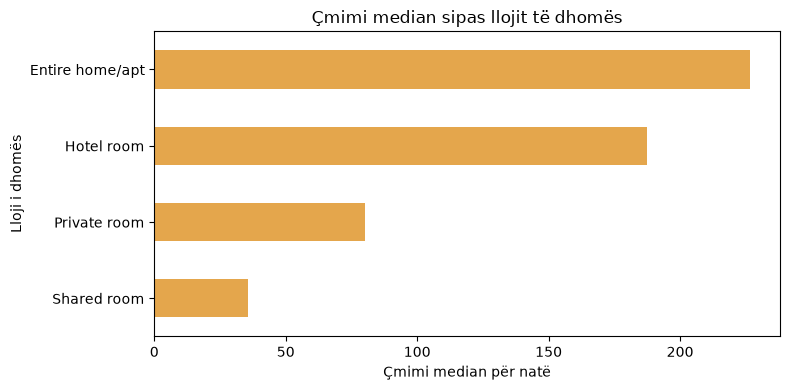

In [10]:
numeric_features = ["accommodates", "bathrooms", "bedrooms", "beds", "availability_365", "amenity_count"]
scaled = analysis[numeric_features].astype(float)
scaled = (scaled - scaled.mean()) / scaled.std(ddof=0).replace(0, 1)
scaled.columns = [f"{col}_z" for col in scaled]
encoded = pd.get_dummies(analysis["room_type"], prefix="room", dtype=int)
print("Shembull i vetive të transformuara:")
display(pd.concat([scaled, encoded], axis=1).head())

by_room = analysis.groupby("room_type")["price"].agg(["count", "median"]).sort_values("median")
by_area = analysis.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"]).sort_values("count", ascending=False)
display(by_room.round(2))
display(by_area.head(10).round(2))
ax = by_room["median"].plot.barh(figsize=(8, 4), color="#e4a64c")
ax.set(xlabel="Çmimi median për natë", ylabel="Lloji i dhomës", title="Çmimi median sipas llojit të dhomës")
plt.tight_layout()
plt.show()

## 7. Kontrolli para/pas dhe ruajtja

Raporti tregon çfarë ndryshoi në secilin hap, çfarë ndodhi me çdo rresht të dataset-it, çfarë ndodhi me mungesat e secilës kolonë dhe nëse ka mbetur ndonjë problem. Dataset-i final ruhet pa ndryshuar skedarin origjinal.

### 7.1 Hapat e pastrimit

In [11]:
display(pd.DataFrame(log))

,hapi,rreshta,kolona,qeliza boshe
0,Fillimi,91954,90,1933263
1,"Kolona boshe, ID, tipe",91954,76,645907
2,Heqja e çmimit të munguar/jo pozitiv,59905,76,289093
3,Plotësimi i zgjedhur i mungesave,59905,76,215401
4,Heqja e çmimeve ekstreme (P99.9 sipas llojit t...,59846,76,215027
5,Shënimi i çmimeve mbi P99,59846,77,215027
6,"Anomali: maximum_nights i kufizuar, bedrooms >...",59846,78,215027
7,Vetitë e reja dhe kategoritë,59846,82,215027


### 7.2 Çfarë ndodhi me rreshtat

Çdo rresht është ose i mbajtur ose i hequr për një arsye. Boshti është logaritmik, sepse ka shumë më tepër rreshta të mbajtur se të hequr.

,rreshta
të mbajtur,59846
hequr: ID e dyfishuar,0
hequr: pa çmim,32049
hequr: çmim <= 0,0
hequr: çmim ekstrem,59


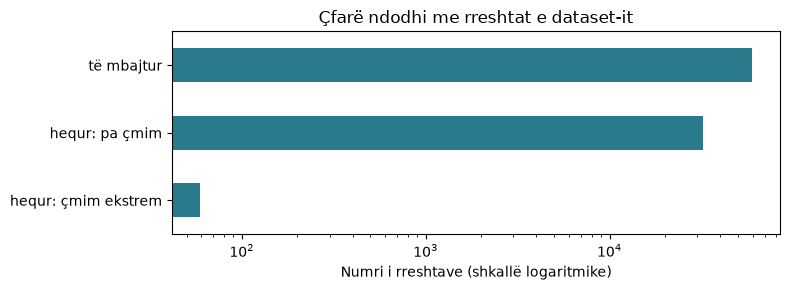

In [12]:
fate = pd.Series({"të mbajtur": len(df), **{f"hequr: {reason}": count for reason, count in removed.items()}})
assert fate.sum() == len(raw), "Çdo rresht duhet të jetë i mbajtur ose i hequr"
display(fate.to_frame("rreshta"))
ax = fate[fate.gt(0)].sort_values().plot.barh(figsize=(8, 3), color="#287a8c")
ax.set(xscale="log", xlabel="Numri i rreshtave (shkallë logaritmike)", title="Çfarë ndodhi me rreshtat e dataset-it")
plt.tight_layout()
plt.show()

### 7.3 Strategjia për mungesat, kolonë për kolonë

Tabela ka një rresht për çdo kolonë që kishte mungesa në dataset-in origjinal, me vendimin dhe arsyen. `veprimi` është njëri nga:
- `kolonë e hequr`: kolona ishte krejt bosh dhe u hoq;
- `plotësuar`: mungesat u plotësuan me një rregull të shpjeguar;
- `rreshta të hequr`: mungesat ishin vetëm te rreshtat e hequr, ndaj te rreshtat e mbajtur nuk mbeti asnjë;
- `lënë bosh`: mungesat u lanë me qëllim.

`mungesa para` dhe `% para` numërojnë të gjitha rreshtat fillestarë; `mungesa pas` dhe `% pas` numërojnë vetëm rreshtat e mbajtur. Kolonat që nuk kishin asnjë mungesë nuk kanë nevojë për vendim dhe mbeten siç janë.

39 nga 90 kolona nuk kishin asnjë mungesë; tabela më poshtë ka 51 kolonat me mungesa.


,kolona
veprimi,
kolonë e hequr,14
plotësuar,5
rreshta të hequr,10
lënë bosh,22


,mungesa para,% para,mungesa pas,% pas,veprimi,arsyeja
neighborhood_overview,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_since,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_response_time,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_response_rate,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_acceptance_rate,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_thumbnail_url,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_neighbourhood,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_total_listings_count,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_verifications,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
neighbourhood,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"


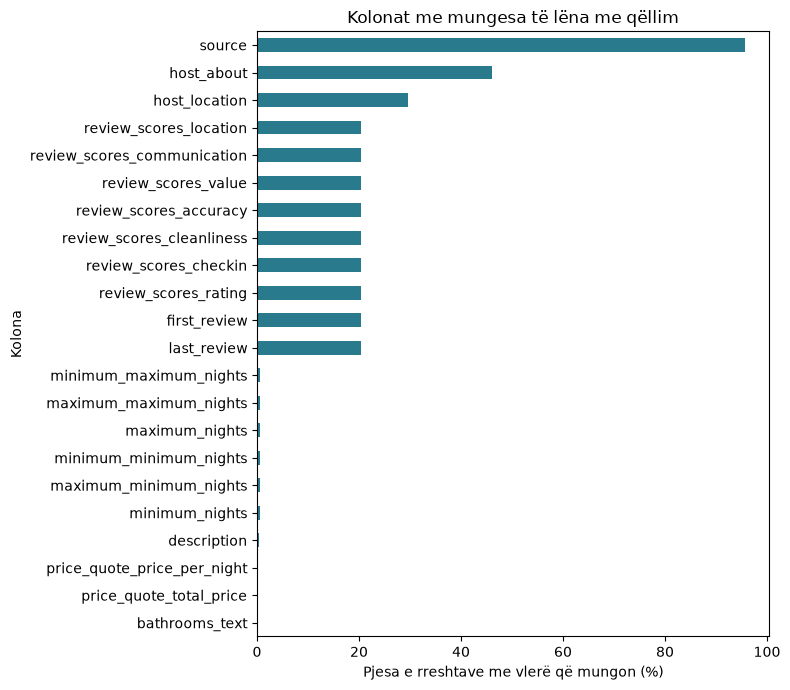

In [13]:
def missing_action(col):
    if col not in df:
        return "kolonë e hequr"
    before = raw.loc[df.index, col].isna().sum()
    after = df[col].isna().sum()
    if after < before:
        return "plotësuar"
    return "rreshta të hequr" if before == 0 else "lënë bosh"

median_fill = "numër; plotësuar me medianën e listimeve me të njëjtin accommodates"
no_reviews = "listimi pa komente nuk ka vlerësim; plotësimi do t'i jepte një notë që nuk e ka marrë kurrë"
reasons = {
    "bathrooms": "rindërtuar nga bathrooms_text ('No bathroom' = 0, 'Half-bath' = 0.5); pjesa e mbetur me medianën sipas accommodates",
    "bedrooms": median_fill,
    "beds": median_fill,
    "has_availability": "nxjerrë nga availability_365: True kur listimi ka ditë të lira",
    "reviews_per_month": "listimi pa komente ka 0 komente në muaj; plotësuar me 0 vetëm kur number_of_reviews = 0",
    "price": "variabla që analizojmë; plotësimi do të sajonte çmime, prandaj listimet pa çmim u hoqën",
    "source": "vlera e vetme është 'previous scrape'; boshllëku do të thotë mbledhje e zakonshme, është etiketë",
    "description": "tekst i lirë; nuk plotësohet me tekst të sajuar",
    "host_location": "tekst i lirë që hosti nuk e ka dhënë; analiza e çmimit nuk e përdor",
    "host_about": "tekst i lirë; një biografi e sajuar do të ishte e gabuar",
    "bathrooms_text": "boshllëk i vogël; bathrooms plotësohet me medianë aty ku mungon",
    "price_quote_total_price": "boshllëk i vogël pas heqjes së listimeve pa çmim; analiza përdor price",
    "price_quote_price_per_night": "boshllëk i vogël pas heqjes së listimeve pa çmim; analiza përdor price",
    "first_review": "listimi pa komente nuk ka datë; plotësimi do t'i jepte një datë që nuk ka ndodhur",
    "last_review": "listimi pa komente nuk ka datë; plotësimi do t'i jepte një datë që nuk ka ndodhur",
}
reasons.update({col: no_reviews for col in raw.columns if col.startswith("review_scores_")})
reasons.update({col: "boshllëk i vogël; analiza e çmimit nuk e kërkon dhe një supozim për netët do të ishte i sajuar"
                for col in raw.columns if "nights" in col})

def reason_for(col, action):
    if action == "kolonë e hequr":
        return "kolona është 100% bosh, pa asnjë informacion"
    if action == "rreshta të hequr":
        return reasons.get(col, "mungesat ishin vetëm te rreshtat e hequr (pa çmim), ndaj nuk ka çfarë të plotësohet")
    return reasons[col]  # një kolonë e re me mungesa kërkon një vendim të shkruar këtu

missing_before = raw.isna().sum()
missing_before = missing_before[missing_before.gt(0)]
missing = pd.DataFrame({
    "mungesa para": missing_before,
    "% para": (missing_before / len(raw) * 100).round(1),
    "mungesa pas": df.isna().sum().reindex(missing_before.index).astype("Int64"),
})
missing["% pas"] = (missing["mungesa pas"] / len(df) * 100).astype(float).round(1)
missing["veprimi"] = [missing_action(col) for col in missing.index]
missing["arsyeja"] = [reason_for(col, action) for col, action in zip(missing.index, missing["veprimi"])]
order = {"kolonë e hequr": 0, "plotësuar": 1, "rreshta të hequr": 2, "lënë bosh": 3}
missing = missing.sort_values("veprimi", key=lambda s: s.map(order), kind="stable")

print(f"{raw.shape[1] - len(missing)} nga {raw.shape[1]} kolona nuk kishin asnjë mungesë; tabela më poshtë ka {len(missing)} kolonat me mungesa.")
display(missing.groupby("veprimi").size().reindex(list(order)).to_frame("kolona"))
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(missing.astype(object).where(missing.notna(), "—"))

kept = missing[missing["veprimi"].eq("lënë bosh")]
ax = (kept["mungesa pas"] / len(df) * 100).sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
ax.set(xlabel="Pjesa e rreshtave me vlerë që mungon (%)", ylabel="Kolona", title="Kolonat me mungesa të lëna me qëllim")
plt.tight_layout()
plt.show()

### 7.4 Kontrollet përfundimtare

Të gjitha vlerat më poshtë duhet të jenë 0. Nëse ndonjëra nuk është, pastrimi ka lënë një problem dhe qeliza ndalon.

In [14]:
checks = pd.Series({
    "çmim që mungon": int(df["price"].isna().sum()),
    "çmim <= 0": int(df["price"].le(0).sum()),
    "ID të dyfishuara": int(df["id"].duplicated().sum()),
    "bathrooms, bedrooms ose beds që mungojnë": int(df[["bathrooms", "bedrooms", "beds"]].isna().sum().sum()),
    "reviews_per_month që mungon": int(df["reviews_per_month"].isna().sum()),
    "has_availability që mungon": int(df["has_availability"].isna().sum()),
    "netë maksimale mbi kufirin": int(df[night_columns].gt(MAX_NIGHTS_CAP).sum().sum()),
})
display(checks.to_frame("numri"))
assert checks.eq(0).all(), "Pas pastrimit kanë mbetur probleme"

,numri
çmim që mungon,0
çmim <= 0,0
ID të dyfishuara,0
"bathrooms, bedrooms ose beds që mungojnë",0
reviews_per_month që mungon,0
has_availability që mungon,0
netë maksimale mbi kufirin,0


### 7.5 Ruajtja

Ruajmë dy skedarë në `dataset/`. Asnjëri nuk futet në Git, dhe dataset-i origjinal mbetet i pandryshuar.

In [15]:
print(f"Rezultati për analizë: {len(analysis):,} rreshta × {analysis.shape[1]} kolona")
print(f"Vlerësime të mungura të ruajtura: {analysis['review_scores_rating'].isna().sum():,}")
output = ROOT / "dataset" / "listings_preprocessed.csv"
full_output = ROOT / "dataset" / "listings_clean_full.csv"
output.parent.mkdir(parents=True, exist_ok=True)
analysis.to_csv(output, index=False)
df.to_csv(full_output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({analysis.shape[1]} kolona)")
print(f"U ruajt: {full_output.relative_to(ROOT)} ({df.shape[1]} kolona)")

Rezultati për analizë: 59,846 rreshta × 18 kolona
Vlerësime të mungura të ruajtura: 12,226
U ruajt: dataset/listings_preprocessed.csv (18 kolona)
U ruajt: dataset/listings_clean_full.csv (82 kolona)
